In [ ]:
import numpy as np
import cv2 as cv
import sys

def construct_yolo_v3():
    f=open('./ch9/coco_names.txt', 'r')
    class_names=[line.strip() for line in f.readlines()]

    model=cv.dnn.readNet('./ch9/yolov3.weights','./ch9/yolov3.cfg')
    layer_names=model.getLayerNames()
    out_layers=[layer_names[i-1] for i in model.getUnconnectedOutLayers()]
    
    return model,out_layers,class_names

def yolo_detect(img,yolo_model,out_layers):
    height,width=img.shape[0],img.shape[1]
    test_img=cv.dnn.blobFromImage(img,1.0/256,(448,448),(0,0,0),swapRB=True)
    
    yolo_model.setInput(test_img)
    output3=yolo_model.forward(out_layers)
    
    box,conf,id=[],[],[]		# 박스, 신뢰도, 부류 번호
    for output in output3:
        for vec85 in output:w
            scores=vec85[5:]
            class_id=np.argmax(scores)
            confidence=scores[class_id]
            if confidence>0.5:	# 신뢰도가 50% 이상인 경우만 취함
                centerx,centery=int(vec85[0]*width),int(vec85[1]*height)
                w,h=int(vec85[2]*width),int(vec85[3]*height)
                x,y=int(centerx-w/2),int(centery-h/2)
                box.append([x,y,x+w,y+h])
                conf.append(float(confidence))
                id.append(class_id)
            
    ind=cv.dnn.NMSBoxes(box,conf,0.5,0.4)
    objects=[box[i]+[conf[i]]+[id[i]] for i in range(len(box)) if i in ind]
    return objects

model,out_layers,class_names=construct_yolo_v3()		# YOLO 모델 생성
colors=np.random.uniform(0,255,size=(len(class_names),3))	# 부류마다 색깔

cap=cv.VideoCapture(0,cv.CAP_DSHOW)
if not cap.isOpened(): sys.exit('카메라 연결 실패')

import time

start=time.time()
n_frame=0
while True:
    ret,frame=cap.read()
    if not ret: sys.exit('프레임 획득에 실패하여 루프를 나갑니다.')
        
    res=yolo_detect(frame,model,out_layers)   
 
    for i in range(len(res)):
        x1,y1,x2,y2,confidence,id=res[i]
        text=str(class_names[id])+'%.3f'%confidence
        cv.rectangle(frame,(x1,y1),(x2,y2),colors[id],2)
        cv.putText(frame,text,(x1,y1+30),cv.FONT_HERSHEY_PLAIN,1.5,colors[id],2)
    
    cv.imshow("Object detection from video by YOLO v.3",frame)
    n_frame+=1
    
    key=cv.waitKey(1) 
    if key==ord('q'): break 

end=time.time()
print('처리한 프레임 수=',n_frame,', 경과 시간=',end-start,'\n초당 프레임 수=',n_frame/(end-start))

cap.release()		# 카메라와 연결을 끊음
cv.destroyAllWindows()

SystemExit: 프레임 획득에 실패하여 루프를 나갑니다.

c:\Users\smart\anaconda3\envs\tf_gpu\lib\site-packages\IPython\core\interactiveshell.py:3587: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
import sys
import cv2 as cv
import numpy as np
import torch


# 1. YOLOv5 모델 사용
def load_yolov5():
    # 'yolov5s' (small), 'yolov5m' (medium), 'yolov5l' (large) 중 선택 가능
    
    model = torch.hub.load('ultralytics/yolov5', 'yolov5s', pretrained=True)
    model.conf = 0.5  # 신뢰도 임계값 0.5이상만 객체로 판단
    return model

#앞에 선언했던 yolov5 모델로 객체 선언
model = load_yolov5()
class_names = model.names  # 클래스 이름 리스트 추출
#클래스별로 다른 색으로 지정하기 위해 색 선언
colors = np.random.uniform(0, 255, size=(len(class_names), 3))

# 캠 연결
cap = cv.VideoCapture(0, cv.CAP_DSHOW)
#캠이 안열렸으면 sys.exit 하기
if not cap.isOpened():
    sys.exit('카메라 연결 실패')
#캠이 있을때
while True:
    #ret 과 frame 받아오기 ret은 비디오 프레임 제대로 가져왔는지 반환값
    ret, frame = cap.read()
    #ret이 없을때
    if not ret:
        sys.exit('프레임 획득 실패')

    # YOLOv5 추론 실행 (RGB 이미지 전달)
    rgb_frame = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
    results = model(rgb_frame)

    # 검출 결과 추출 x1, y1, x2, y2, confidence, class_id 총 4개 받아옴
    detections = results.xyxy[0].cpu().numpy()

    # 추출해온 detections에서 꼭짓점 위치랑 정확도 클래스명 저장
    for det in detections:
        x1, y1, x2, y2, confidence, class_id = det
        x1, y1, x2, y2 = int(x1), int(y1), int(x2), int(y2)
        class_id = int(class_id)
        text = f'{class_names[class_id]} {confidence:.3f}'
        color = [int(c) for c in colors[class_id]]
        #삼각형 그리는 함수로 삼각형 그리기
        cv.rectangle(frame, (x1, y1), (x2, y2), color, 2)
        #텍스트 출력
        cv.putText(
            frame,
            text,
            (x1, max(y1 - 10, 15)),
            cv.FONT_HERSHEY_PLAIN,
            1.5,
            color,
            2,
        )
#영상 보여주기
    cv.imshow('Object detection from video by YOLOv5', frame)
#q누르면 끄기
    key = cv.waitKey(1)
    if key == ord('q'):
        break

cap.release()
cv.destroyAllWindows()

In [ ]:
from tensorflow import keras
import numpy as np
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras import layers
import os
import random
import cv2 as cv

input_dir='./datasets/oxford_pets/images/images/'
target_dir='./datasets/oxford_pets/annotations/annotations/trimaps/'
img_siz=(160,160)	# 모델에 입력되는 영상 크기
n_class=3		# 분할 레이블 (1:물체, 2:배경, 3:경계)
batch_siz=32		# 미니 배치 크기

img_paths=sorted([os.path.join(input_dir,f) for f in os.listdir(input_dir) if f.endswith('.jpg')])
label_paths=sorted([os.path.join(target_dir,f) for f in os.listdir(target_dir) if f.endswith('.png') and not f.startswith('.')])

class OxfordPets(keras.utils.Sequence):
    def __init__(self, batch_size,img_size,img_paths,label_paths):
        self.batch_size=batch_size
        self.img_size=img_size
        self.img_paths=img_paths
        self.label_paths=label_paths

    def __len__(self):
        return len(self.label_paths)//self.batch_size

    def __getitem__(self,idx):
        i=idx*self.batch_size
        batch_img_paths=self.img_paths[i:i+self.batch_size]
        batch_label_paths=self.label_paths[i:i+self.batch_size]
        x=np.zeros((self.batch_size,)+self.img_size+(3,),dtype="float32")
        for j,path in enumerate(batch_img_paths):
            img=load_img(path,target_size=self.img_size)
            x[j]=img
        y=np.zeros((self.batch_size,)+self.img_size+(1,),dtype="uint8")
        for j,path in enumerate(batch_label_paths):
            img=load_img(path,target_size=self.img_size,color_mode="grayscale")
            y[j]=np.expand_dims(img,2)
            y[j]-=1		# 부류 번호를 1,2,3에서 0,1,2로 변환
        return x,y

def make_model(img_size,num_classes):
    inputs=keras.Input(shape=img_size+(3,))

    # U-net의 다운 샘플링(축소 경로)
    x=layers.Conv2D(32,3,strides=2,padding='same')(inputs)
    x=layers.BatchNormalization()(x)
    x=layers.Activation('relu')(x)
    previous_block_activation=x		# 지름길 연결을 위해

    for filters in [64,128,256]:
        x=layers.Activation('relu')(x)
        x=layers.SeparableConv2D(filters,3,padding='same')(x)
        x=layers.BatchNormalization()(x)
        x=layers.Activation('relu')(x)
        x=layers.SeparableConv2D(filters,3,padding='same')(x)
        x=layers.BatchNormalization()(x)
        x=layers.MaxPooling2D(3,strides=2,padding='same')(x)
        residual=layers.Conv2D(filters,1,strides=2,padding='same')(previous_block_activation)
        x=layers.add([x,residual])	# 지름길 연결  
        previous_block_activation=x	# 지름길 연결을 위해

    # U-net의 업 샘플링(확대 경로)
    for filters in [256, 128, 64, 32]:
        x=layers.Activation('relu')(x)
        x=layers.Conv2DTranspose(filters,3,padding='same')(x)
        x=layers.BatchNormalization()(x)
        x=layers.Activation('relu')(x)
        x=layers.Conv2DTranspose(filters,3,padding='same')(x)
        x=layers.BatchNormalization()(x)
        x=layers.UpSampling2D(2)(x)
        residual=layers.UpSampling2D(2)(previous_block_activation)
        residual=layers.Conv2D(filters,1,padding='same')(residual)
        x=layers.add([x,residual])	# 지름길 연결
        previous_block_activation=x	# 지름길 연결을 위해

    outputs=layers.Conv2D(num_classes,3,activation='softmax',padding='same')(x)
    model=keras.Model(inputs, outputs)	# 모델 생성
    return model

model=make_model(img_siz,n_class)		# 모델 생성

random.Random(1).shuffle(img_paths)
random.Random(1).shuffle(label_paths)
test_samples=int(len(img_paths)*0.1)	# 10%를 테스트 집합으로 사용
train_img_paths=img_paths[:-test_samples]
train_label_paths=label_paths[:-test_samples]
test_img_paths=img_paths[-test_samples:]
test_label_paths=label_paths[-test_samples:]

train_gen=OxfordPets(batch_siz,img_siz,train_img_paths,train_label_paths) # 훈련 집합
test_gen=OxfordPets(batch_siz,img_siz,test_img_paths,test_label_paths) # 검증 집합

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
cb=[keras.callbacks.ModelCheckpoint('oxford_seg.h5',save_best_only=True)] # 학습 결과 자동 저장
model.fit(train_gen,epochs=30,validation_data=test_gen,callbacks=cb)

preds=model.predict(test_gen)	# 예측

cv.imshow('Sample image',cv.imread(test_img_paths[0]))# 0번 영상 디스플레이
cv.imshow('Segmentation label',cv.imread(test_label_paths[0])*64)
cv.imshow('Segmentation prediction',preds[0]) # 0번 영상 예측 결과 디스플레이

cv.waitKey()
cv.destroyAllWindows()

FileNotFoundError: [WinError 3] 지정된 경로를 찾을 수 없습니다: './datasets/oxford_pets/images/images/'

In [ ]:
mkdir -p ./datasets/oxford_pets
cd ./datasets/oxford_pets

# 이미지 및 주석 파일 다운로드
wget https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
wget https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz

# 압축 해제
tar -zxvf images.tar.gz
tar -zxvf annotations.tar.gz

SyntaxError: invalid syntax (3799824450.py, line 1)

In [ ]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

# 그 다음 PixelLib 불러오기
from pixellib.semantic import semantic_segmentation
import cv2 as cv

seg = semantic_segmentation()

ImportError: cannot import name 'BatchNormalization' from 'tensorflow.python.keras.layers' (c:\Users\smart\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\python\keras\layers\__init__.py)

In [3]:
from pixellib.semantic import semantic_segmentation
import cv2 as cv

seg=semantic_segmentation()
seg.load_ade20k_model('./ch9/deeplabv3_xception65_ade20k.h5')

img_fname='./ch9/busy_street.jpg'
seg.segmentAsAde20k(img_fname,output_image_name='image_new.jpg')
info1,img_segmented1=seg.segmentAsAde20k(img_fname)
info2,img_segmented2=seg.segmentAsAde20k(img_fname,overlay=True)

cv.imshow('Image original',cv.imread(img_fname))
cv.imshow('Image segmention',img_segmented1)
cv.imshow('Image segmention overlayed',img_segmented2)

cv.waitKey()
cv.destroyAllWindows()

1/1 [==============================] - 14s 14s/step
Processed Image saved successfuly in your current working directory.
1/1 [==============================] - 1s 1s/step


In [2]:
from pixellib.semantic import semantic_segmentation
import cv2 as cv

cap=cv.VideoCapture(0)

seg_video=semantic_segmentation()
seg_video.load_ade20k_model('./ch9/deeplabv3_xception65_ade20k.h5')

seg_video.process_camera_ade20k(cap,overlay=True,frames_per_second=2,output_video_name='output_video.mp4',show_frames=True,frame_name='Pixellib')

cap.release()
cv.destroyAllWindows()

Instructions for updating:
Colocations handled automatically by placer.


c:\Users\smart\anaconda3\envs\pixellib_clean\lib\site-packages\tf_keras\src\engine\training_v1.py:2354: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorFlow 2.0, as `updates` are applied automatically.
  updates=self.state_updates,


In [3]:
from pixellib.instance import instance_segmentation
import cv2 as cv

seg=instance_segmentation()
seg.load_model("./mask_rcnn_coco.h5")

img_fname='./ch9/busy_street.jpg'
info,img_segmented=seg.segmentImage(img_fname,show_bboxes=True)

cv.imshow('Image segmention overlayed',img_segmented)

cv.waitKey()
cv.destroyAllWindows()

c:\Users\smart\anaconda3\envs\pixellib_clean\lib\site-packages\keras\src\engine\training_v1.py:2359: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorFlow 2.0, as `updates` are applied automatically.
  updates=self.state_updates,


In [14]:
from pixellib.instance import instance_segmentation
import cv2 as cv

seg = instance_segmentation()
# Mask R-CNN 모델 로드 (COCO 데이터셋 기준 80개 클래스)
seg.load_model("./ch9/mask_rcnn_coco.h5")

img_fname = './ch9/busy_street.jpg'

# 인스턴스 세그멘테이션 수행
info, img_segmented = seg.segmentImage(img_fname, show_bboxes=True)

# info['class_ids'] : 감지된 각 객체의 클래스 ID 리스트
# info['rois'] : 각 객체의 바운딩 박스 좌표
object_counts = len(info['class_ids'])
print(f"총 감지된 개별 객체 수: {object_counts}개")

# 클래스별 개수 집계 예시
from collections import Counter
# info['class_ids']의 ID별 개수 산출
counts_by_class = Counter(info['class_ids'])
print("클래스 ID별 감지 개수:", counts_by_class)

cv.imshow('Instance Segmentation', img_segmented)
cv.waitKey(0)
cv.destroyAllWindows()

총 감지된 개별 객체 수: 100개
클래스 ID별 감지 개수: Counter({44: 100})


In [18]:
import cv2 as cv
from collections import Counter
import os
from pixellib.instance import instance_segmentation

# 1. 파일 존재 여부 사전 확인 (갑작스러운 오류 방지)
img_fname = "./street.webp"
model_fname = "./ch9/mask_rcnn_coco.h5"

if not os.path.exists(img_fname):
    raise FileNotFoundError(f"이미지 파일을 찾을 수 없습니다: {img_fname}")
if not os.path.exists(model_fname):
    raise FileNotFoundError(
        f"가중치 모델 파일을 찾을 수 없습니다: {model_fname}"
    )

# 2. 원본 이미지 불러오기
img_original = cv.imread(img_fname)
if img_original is None:
    raise ValueError(
        f"이미지를 로드하지 못했습니다. 파일이 손상되었거나 지원하지 않는 형식입니다: {img_fname}"
    )

# 3. 인스턴스 세그멘테이션 객체 생성 및 모델 로드
seg = instance_segmentation()
seg.load_model(model_fname)

# 4. 세그멘테이션 수행
info, img_segmented = seg.segmentImage(img_fname, show_bboxes=True)

# COCO 데이터셋 81개 표준 클래스 이름 리스트
coco_class_names = [
    "BG",
    "person",
    "bicycle",
    "car",
    "motorcycle",
    "airplane",
    "bus",
    "train",
    "truck",
    "boat",
    "traffic light",
    "fire hydrant",
    "stop sign",
    "parking meter",
    "bench",
    "bird",
    "cat",
    "dog",
    "horse",
    "sheep",
    "cow",
    "elephant",
    "bear",
    "zebra",
    "giraffe",
    "backpack",
    "umbrella",
    "handbag",
    "tie",
    "suitcase",
    "frisbee",
    "skis",
    "snowboard",
    "sports ball",
    "kite",
    "baseball bat",
    "baseball glove",
    "skateboard",
    "surfboard",
    "tennis racket",
    "bottle",
    "wine glass",
    "cup",
    "fork",
    "knife",
    "spoon",
    "bowl",
    "banana",
    "apple",
    "sandwich",
    "orange",
    "broccoli",
    "carrot",
    "hot dog",
    "pizza",
    "donut",
    "cake",
    "chair",
    "couch",
    "potted plant",
    "bed",
    "dining table",
    "toilet",
    "tv",
    "laptop",
    "mouse",
    "remote",
    "keyboard",
    "cell phone",
    "microwave",
    "oven",
    "toaster",
    "sink",
    "refrigerator",
    "book",
    "clock",
    "vase",
    "scissors",
    "teddy bear",
    "hair drier",
    "toothbrush",
]

# 클래스별 개수 집계
class_ids = info["class_ids"]
counts = Counter(class_ids)

# 세그멘테이션 이미지 좌측 상단에 텍스트 출력
y0, dy = 30, 30
for i, (class_id, count) in enumerate(counts.items()):
    if class_id < len(coco_class_names):
        name = coco_class_names[class_id]
    else:
        name = f"class_{class_id}"

    text = f"{name}: {count}"
    y = y0 + i * dy

    # 텍스트 외곽선 및 글씨 그리기
    cv.putText(
        img_segmented,
        text,
        (10, y),
        cv.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 0),
        4,
        cv.LINE_AA,
    )
    cv.putText(
        img_segmented,
        text,
        (10, y),
        cv.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 0, 255),
        2,
        cv.LINE_AA,
    )

# 5. 원본 이미지와 결과 이미지를 각각 별도의 창으로 표시
cv.imshow("Original Image", img_original)
cv.imshow("Segmented Image Overlay", img_segmented)

cv.waitKey(0)
cv.destroyAllWindows()

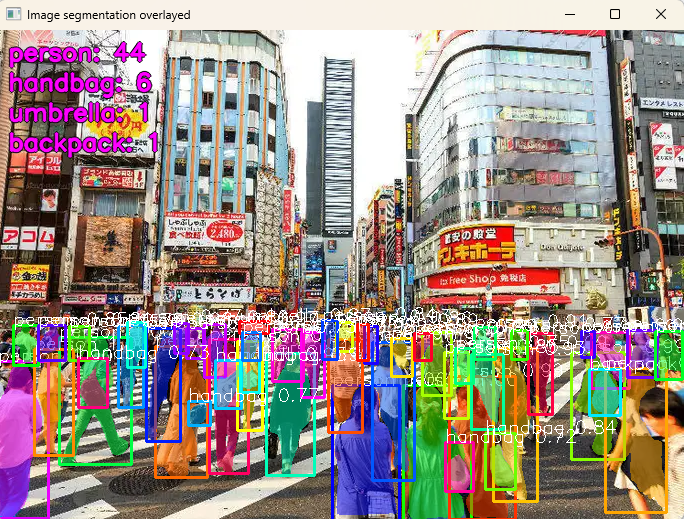

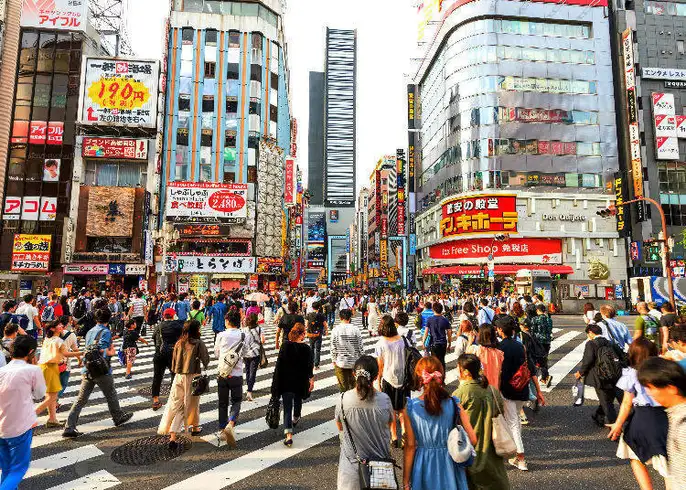